# Stop-validity review for routes 8 and 66: when the buses really moved, and whether they stopped at three corners

TODO.md Phase 1, Next, "Review the stop-validity windows against the archived GTFS". Exploratory, no spec. It follows
`notebooks/gtfs_history_routes_8_66.ipynb` (`docs/2026-11-22-gtfs-history-routes-8-66.md`), which found 26 of the 38
committed windows in `notebooks/routes_8_65_66_stop_validity.json` disagreeing with the schedule.

The owner's rules for the review (2026-11-23):

1. Where the pings date a change to a different service day than the schedule, the pings are ground truth: the actual
   driving is the schedule in effect that day.
2. A corner served at different spots under different stop ids, by pattern or by date, is one corner, served.
3. For the three corners the schedule leaves without a stop for a while (Orleans & Chicago on 6662 before 2025-09-28,
   Wells & Chicago on 6665 before 2025-11-23, `15341` on 9376 from 2025-08-17 to 2025-11-22), compare the time buses
   take from the stop before the corner to the stop after it, with and without a stop there.

Section 1 applies rule 1. The committed dates come from the longest `pdist` reported on each calendar day, a statistic
of a derived field; this reads where the buses were (lat/lon, observed) instead, and section 1b shows what set those
longest values.
Section 2 answers 3. Contains data from [Transitland](https://www.transit.land/terms): the paths and stop lists are
read from archived GTFS versions (ADR-013). Changes no window: it informs the review. Not for riders (ADR-002).

In [1]:
%matplotlib inline

import json
import re
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pacsv
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from cta import mansueto_raw

_style = REPO_ROOT / "notebooks" / "cta_analysis.mplstyle"
if _style.is_file():
    plt.style.use(_style)
plt.rcParams["figure.dpi"] = 72  # keeps the committed notebook small
pd.set_option("display.max_rows", 200, "display.max_columns", 40, "display.width", 200)

RAW_DIR = REPO_ROOT / "data" / "mansueto_raw"  # Mansueto raw day CSVs, as scripts/route_run_level.py caches them
FEED_DIR = REPO_ROOT / "data" / "gtfs" / "feed_versions"  # from notebooks/gtfs_history_routes_8_66.ipynb section 1
VALIDITY = json.loads((REPO_ROOT / "notebooks" / "routes_8_65_66_stop_validity.json").read_text())
PIDS = ["9368", "9376", "6662", "6665"]
VERSION = {  # one archived version per path, each with clean shapes.txt distances for these pids
    "old": "78428dc43416f3a0be254cfcb2ea05ed2f65ebc9",   # fetched 2025-07-11: the routes before the closures
    "det1": "c07e68317b3e4452accfc9f09805727a88937458",  # fetched 2025-10-27: first detours (route 8 from 2025-08-17, 66 from 2025-09-28)
    "det2": "81c806bbfb678eb3e3a8292a0a83f768bdb1009d",  # fetched 2026-05-30: today's detours (from 2025-11-23)
}
SHAPE_ID = {"old": "673", "det1": "675", "det2": "679"}  # schedule-generation prefix in force on the sample days; pid = shape_id % 100,000
PATHS = {"9368": ["old", "det1", "det2"], "9376": ["old", "det1", "det2"], "6662": ["old", "det1"], "6665": ["old", "det1", "det2"]}  # 6662's 2025-11-23 change kept its path
FT_PER_DEG_LAT = 364_000.0  # local projection only
ON_PATH_FT = 100  # 2026-11-22 note: pings sit within 14 ft of their shape at the 95th percentile away from terminals

## Reading the paths and the raw days

A path is the GTFS shape of a pattern; the stops and their distances come from `stop_times.txt` (playbook, "GTFS
`shapes.txt` distances can run far past the last stop"; the three versions above are clean for these shapes). Raw day
files are fetched once into `data/mansueto_raw/` (about 40 MB each).

In [2]:
_STR = {c: pa.string() for c in ["route_id", "trip_id", "shape_id", "stop_id", "service_id"]}


def _read(z, name, cols=None):
    return pacsv.read_csv(z.open(name), convert_options=pacsv.ConvertOptions(column_types=_STR, include_columns=cols)).to_pandas()


SHAPES, PATTERN, STOPS = {}, {}, {}
for path, sha1 in VERSION.items():
    z = zipfile.ZipFile(FEED_DIR / f"{sha1}.zip")
    trips, shapes = _read(z, "trips.txt"), _read(z, "shapes.txt")
    st = _read(z, "stop_times.txt", ["trip_id", "stop_id", "stop_sequence", "shape_dist_traveled"])
    STOPS[path] = _read(z, "stops.txt").set_index("stop_id")
    for pid in PIDS:
        if path not in PATHS[pid]:
            continue
        shape_id = SHAPE_ID[path] + pid.zfill(5)
        trip = trips.loc[trips["shape_id"] == shape_id, "trip_id"].iloc[0]
        PATTERN[(path, pid)] = st[st["trip_id"] == trip].sort_values("stop_sequence")[["stop_id", "shape_dist_traveled"]].reset_index(drop=True)
        SHAPES[(path, pid)] = shapes[shapes["shape_id"] == shape_id].sort_values("shape_pt_sequence").reset_index(drop=True)
        assert abs(SHAPES[(path, pid)]["shape_dist_traveled"].max() - PATTERN[(path, pid)]["shape_dist_traveled"].max()) < 100


def project(shape: pd.DataFrame, lat, lon) -> tuple[np.ndarray, np.ndarray]:
    """Distance along the shape (feet, its own distances) of each point's projection, and the point's distance off it."""
    lat, lon = np.atleast_1d(lat).astype(float), np.atleast_1d(lon).astype(float)
    kx = FT_PER_DEG_LAT * np.cos(np.radians(41.9))
    x, y = shape["shape_pt_lon"].to_numpy() * kx, shape["shape_pt_lat"].to_numpy() * FT_PER_DEG_LAT
    d = shape["shape_dist_traveled"].to_numpy(float)
    ax, ay, vx, vy = x[:-1], y[:-1], np.diff(x), np.diff(y)
    seg2 = np.where(vx**2 + vy**2 == 0, 1e-9, vx**2 + vy**2)
    along, off = np.empty(len(lat)), np.empty(len(lat))
    for i in range(0, len(lat), 2000):
        px, py = (lon[i:i + 2000] * kx)[:, None], (lat[i:i + 2000] * FT_PER_DEG_LAT)[:, None]
        t = np.clip(((px - ax) * vx + (py - ay) * vy) / seg2, 0, 1)
        o2 = (ax + t * vx - px) ** 2 + (ay + t * vy - py) ** 2
        k = o2.argmin(axis=1)
        r = np.arange(len(k))
        along[i:i + 2000], off[i:i + 2000] = d[:-1][k] + t[r, k] * np.diff(d)[k], np.sqrt(o2[r, k])
    return along, off


def raw_day(day: str, pids=PIDS) -> pd.DataFrame:
    x = mansueto_raw.read_day(mansueto_raw.fetch_day(day, RAW_DIR), pids=pids)
    return x[x["data_date"] == day]  # each file also holds a few previous-day fixes

## 1. When the buses moved (rule 1)

For each day, the pings of each pid inside the area of the closures are classed by the paths they lie on (within
100 ft): only on the old path, only on the first detour, only on the second. A path-only count near zero while
another's is in the hundreds says which route the buses drove. *Section jumps* counts consecutive pings of one trip
that land on opposite sides of the closed section (Grand to Division for route 8, Grand to Chicago for route 66 west);
it is 0 to 22 on a normal day (a 300 s poll can straddle the 0.85 miles of route 8's section) and 32 to 101 when
Bus Tracker stops reporting buses while they cross it. Days were read around every change; the clean October days are section 2's.

In [3]:
AREA = {"lat": (41.884, 41.906), "lon": (-87.660, -87.628)}  # Halsted, Chicago Ave and the river between Lake and North Ave
SECTION = {"9368": (41.8913, 41.9036), "9376": (41.8913, 41.9036), "6665": (41.8913, 41.8966)}  # Grand to Division; Grand to Chicago
DRIVING_DAYS = ["2025-07-29", "2025-08-01", "2025-08-03", "2025-08-04", "2025-08-05", "2025-08-16", "2025-08-17",
                "2025-09-26", "2025-09-27", "2025-09-28", "2025-09-29", "2025-10-28", "2025-10-29", "2025-10-30",
                "2025-10-31", "2025-11-01", "2025-11-02", "2025-11-03", "2025-11-04", "2025-11-05", "2025-11-06",
                "2025-11-07", "2025-11-08", "2025-11-09", "2025-11-10", "2025-11-11", "2025-11-12", "2025-11-22",
                "2025-11-23", "2025-11-24", "2025-11-25"]
DRIVING_DAYS = sorted(set(DRIVING_DAYS) | {f"2025-08-{d:02d}" for d in range(6, 16)} | {f"2025-11-{d:02d}" for d in range(13, 22)})  # 2026-11-27: every day of the unreported periods


def section_jumps(g: pd.DataFrame, south: float, north: float) -> int:
    g = g.sort_values(["vehicle_id", "origtatripno", "vehicle_ts"])
    same = (g["vehicle_id"] == g["vehicle_id"].shift(-1)) & (g["origtatripno"] == g["origtatripno"].shift(-1))
    a, b = g["lat"].to_numpy(), g["lat"].shift(-1).to_numpy()
    return int((same.to_numpy() & (((a < south) & (b > north)) | ((a > north) & (b < south)))).sum())


rows = []
for day in DRIVING_DAYS:
    x = raw_day(day)
    for pid, g in x.groupby("pid"):
        box = g[g["lat"].between(*AREA["lat"]) & g["lon"].between(*AREA["lon"])]
        off = {p: project(SHAPES[(p, pid)], box["lat"], box["lon"])[1] for p in PATHS[pid]}
        r = {"day": day, "pid": pid}
        for p in PATHS[pid]:
            r[f"only_{p}"] = int(((off[p] < ON_PATH_FT) & np.all([off[o] >= ON_PATH_FT for o in PATHS[pid] if o != p], axis=0)).sum())
        r["section_jumps"] = section_jumps(g, *SECTION[pid]) if pid in SECTION else None
        rows.append(r)
DRIVING = pd.DataFrame(rows)
DRIVING["weekday"] = pd.to_datetime(DRIVING["day"]).dt.day_name().str[:3]
for pid in PIDS:
    print(pid)
    display(DRIVING[DRIVING["pid"] == pid].drop(columns="pid").set_index("day").dropna(axis=1, how="all"))

9368


,only_old,only_det1,section_jumps,only_det2,weekday
day,,,,,
2025-07-29,108,0,7.0,0.0,Tue
2025-08-01,123,0,5.0,0.0,Fri
2025-08-03,62,0,4.0,0.0,Sun
2025-08-04,18,4,67.0,0.0,Mon
2025-08-05,0,2,99.0,0.0,Tue
2025-08-06,0,5,87.0,0.0,Wed
2025-08-07,0,10,92.0,0.0,Thu
2025-08-08,0,5,76.0,0.0,Fri
2025-08-09,0,0,68.0,0.0,Sat


9376


,only_old,only_det1,section_jumps,only_det2,weekday
day,,,,,
2025-07-29,70,0,22.0,0.0,Tue
2025-08-01,70,0,18.0,0.0,Fri
2025-08-03,40,0,18.0,0.0,Sun
2025-08-04,18,2,67.0,0.0,Mon
2025-08-05,3,4,93.0,0.0,Tue
2025-08-06,0,4,92.0,0.0,Wed
2025-08-07,0,6,93.0,0.0,Thu
2025-08-08,1,0,66.0,0.0,Fri
2025-08-09,0,1,69.0,0.0,Sat


6662


,only_old,only_det1,weekday
day,,,
2025-07-29,173,0,Tue
2025-08-01,165,0,Fri
2025-08-03,98,0,Sun
2025-08-04,160,0,Mon
2025-08-05,199,0,Tue
2025-08-06,180,0,Wed
2025-08-07,160,0,Thu
2025-08-08,165,0,Fri
2025-08-09,129,0,Sat


6665


,only_old,only_det1,section_jumps,only_det2,weekday
day,,,,,
2025-07-29,143,0,0.0,0.0,Tue
2025-08-01,139,0,0.0,0.0,Fri
2025-08-03,92,0,0.0,0.0,Sun
2025-08-04,138,0,0.0,0.0,Mon
2025-08-05,144,0,0.0,0.0,Tue
2025-08-06,141,0,0.0,1.0,Wed
2025-08-07,136,0,0.0,0.0,Thu
2025-08-08,132,0,0.0,0.0,Fri
2025-08-09,106,0,0.0,0.0,Sat


The change dates three ways: the committed windows (the first calendar day whose longest `pdist` fits the new
pattern, `geometry_changes` in `notebooks/routes_8_65_66_pids.json`), the archived schedule (2026-11-22 note), and the
driving read above.

In [4]:
CHANGES = pd.DataFrame([
    # pattern, change, committed (first calendar day whose longest pdist fits the new pattern), schedule (GTFS), driving (this section), interim before it
    ("8 south (9368)", "first detour", "2025-08-17", "2025-08-17", "2025-08-17", "2025-08-04 to 08-16"),
    ("8 north (9376)", "first detour", "2025-08-17", "2025-08-17", "2025-08-17", "2025-08-04 to 08-16"),
    ("66 east (6662)", "detour", "2025-09-27", "2025-09-28", "2025-09-28", ""),
    ("66 west (6665)", "first detour", "2025-09-28", "2025-09-28", "2025-09-28", ""),
    ("8 north (9376)", "second detour", "2025-11-23", "2025-11-23", "2025-11-23", "2025-11-07 to 11-22"),
    ("66 west (6665)", "second detour", "2025-11-24", "2025-11-23", "2025-11-23", "2025-10-31 to 11-22"),
    ("8 south (9368)", "second detour", "2025-11-25", "2025-11-23", "2025-11-23", "2025-11-07 to 11-22"),
], columns=["pattern", "change", "committed", "schedule", "driving", "interim_unreported"])
display(CHANGES)

,pattern,change,committed,schedule,driving,interim_unreported
0,8 south (9368),first detour,2025-08-17,2025-08-17,2025-08-17,2025-08-04 to 08-16
1,8 north (9376),first detour,2025-08-17,2025-08-17,2025-08-17,2025-08-04 to 08-16
2,66 east (6662),detour,2025-09-27,2025-09-28,2025-09-28,
3,66 west (6665),first detour,2025-09-28,2025-09-28,2025-09-28,
4,8 north (9376),second detour,2025-11-23,2025-11-23,2025-11-23,2025-11-07 to 11-22
5,66 west (6665),second detour,2025-11-24,2025-11-23,2025-11-23,2025-10-31 to 11-22
6,8 south (9368),second detour,2025-11-25,2025-11-23,2025-11-23,2025-11-07 to 11-22


## 1b. What set the committed dates

`pdist` is derived: Bus Tracker projects the GPS fix onto the pattern it holds for the trip. On each of the four days
where the committed date and the driving date differ, each ping's GPS position is projected onto both candidate paths.
Where the paths have diverged by more than 1,000 ft, the test is which projection reproduces the reported `pdist`
within 200 ft. Then come the pings whose `pdist` exceeds the shorter pattern's length by more than 0.05 mi, the
pings that decide a "longest `pdist`" date.

In [5]:
CHANGEOVER = [("2025-09-27", "6662", "old", "det1"), ("2025-11-23", "6665", "det1", "det2"),
              ("2025-11-23", "9368", "det1", "det2"), ("2025-11-24", "9368", "det1", "det2")]
LENGTH_SLACK_FT = 0.05 * 5280  # the rule that dated geometry_changes: longest pdist within 0.05 mi of a pattern's length
fits, longest = [], []
for day, pid, a, b in CHANGEOVER:
    x = raw_day(day, [pid])
    pa, _ = project(SHAPES[(a, pid)], x["lat"], x["lon"])
    pb, _ = project(SHAPES[(b, pid)], x["lat"], x["lon"])
    past = np.abs(pa - pb) > 1_000
    ra, rb = (x["pdist"].to_numpy() - pa)[past], (x["pdist"].to_numpy() - pb)[past]
    fits.append({"day": day, "pid": pid, "pings where the paths differ": int(past.sum()),
                 f"pdist fits the earlier path": f"{(np.abs(ra) < 200).mean():.0%} ({a})", "pdist fits the later path": f"{(np.abs(rb) < 200).mean():.0%} ({b})"})
    shorter = min(PATTERN[(p, pid)]["shape_dist_traveled"].max() for p in (a, b))
    big = x["pdist"].to_numpy() > shorter + LENGTH_SLACK_FT
    for i in np.flatnonzero(big):
        longest.append({"day": day, "pid": pid, "local time": x["vehicle_ts"].iloc[i].tz_convert("America/Chicago").strftime("%H:%M"),
                        "vehicle": x["vehicle_id"].iloc[i], "trip": x["origtatripno"].iloc[i], "pdist": int(x["pdist"].iloc[i]),
                        "fits": a if abs(x["pdist"].iloc[i] - pa[i]) < abs(x["pdist"].iloc[i] - pb[i]) else b})
display(pd.DataFrame(fits))
display(pd.DataFrame(longest))

,day,pid,pings where the paths differ,pdist fits the earlier path,pdist fits the later path
0,2025-09-27,6662,888,100% (old),0% (det1)
1,2025-11-23,6665,66,0% (det1),100% (det2)
2,2025-11-23,9368,742,1% (det1),99% (det2)
3,2025-11-24,9368,1332,1% (det1),99% (det2)


,day,pid,local time,vehicle,trip,pdist,fits
0,2025-09-27,6662,23:24,2025,267694636,50160,det1
1,2025-11-23,6665,01:29,8682,267694801,49799,det1
2,2025-11-23,6665,01:34,8682,267694801,49799,det1
3,2025-11-23,6665,01:39,8682,267694801,49799,det1
4,2025-11-23,6665,01:44,8682,267694801,49819,det1
5,2025-11-23,9368,00:14,1287,267698789,81065,det1
6,2025-11-24,9368,19:49,1286,267681506,81548,det1


On all four days, 99% to 100% of `pdist` values fit the path the buses drove. So Bus Tracker measured along the right
geometry, and the day-or-two offsets come from the statistic. One trip set each committed date:
- **6662 on 2025-09-27:** the last old-route trip of the night (vehicle 2025) drove Chicago Avenue throughout, and its
  final ping at 23:24, at the east terminal both paths share, reports a detour-pattern `pdist`.
- **6665 and 9368 on 2025-11-23:** an owl trip just after midnight that belongs to the previous service day (the raw
  files are calendar days, playbook gotcha) was still, rightly, on the old pattern.
- **9368 on 2025-11-24:** one evening trip (vehicle 1286) was measured along the old pattern for its whole run and went
  unreported through the detour section, while every other trip that day was measured along today's detour.

## 1c. What "drop" removes on the unreported days (owner, 2026-11-28)

The owner chose to drop arrivals the pings did not observe on the unreported days. The question is which stops of
today's patterns that covers, beyond what the reviewed windows already drop. Mansueto joins its arrivals to these
patterns. For each stop in the closures' area: the share of the day's trips with a ping within 100 m of it
(`cta.stop_validity.MAX_STOP_PING_DISTANCE_FT`), median over the unreported days, against normal days before and
after. A stop the pings skipped drops to 0.

In [6]:
from cta import bustracker, stop_validity

AREA_STOPS = (41.884, 41.910, -87.662, -87.628)  # Lake to North Ave, Ashland-ish to Wells: the closures' area
UNREPORTED = {("9368", "9376"): {"Aug interim": ("2025-08-04", "2025-08-16"), "Nov interim": ("2025-11-07", "2025-11-22"),
                                 "normal Jul": ["2025-07-22", "2025-07-23", "2025-07-24", "2025-07-29", "2025-08-01"],
                                 "normal Oct": ["2025-10-28", "2025-10-29", "2025-10-30", "2025-11-04", "2025-11-05"]},
              ("6665",): {"interim": ("2025-10-31", "2025-11-22"),
                          "normal Oct": ["2025-10-21", "2025-10-22", "2025-10-23", "2025-10-28", "2025-10-29", "2025-10-30"],
                          "normal Nov 23 to 25": ["2025-11-23", "2025-11-24", "2025-11-25"]}}


def feet_apart(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * 20_902_260.0 * np.arcsin(np.sqrt(a))  # cta.geo.EARTH_RADIUS_FEET


def trip_share(pids, days, stops):
    out = []
    for day in days:
        x = raw_day(day, list(pids))
        for pid in pids:
            p = x[x["pid"] == pid]
            trips = p["vehicle_id"] + "|" + p["origtatripno"]
            for s in stops[stops["pid"] == pid].itertuples():
                near = feet_apart(p["lat"].to_numpy(), p["lon"].to_numpy(), s.lat, s.lon) <= stop_validity.MAX_STOP_PING_DISTANCE_FT
                out.append({"pid": pid, "stop_id": s.stpid, "name": s.stpnm, "share": trips[near].nunique() / max(trips.nunique(), 1)})
    return pd.DataFrame(out).groupby(["pid", "stop_id", "name"])["share"].median()


windows = {(r["from_pid"], r["stop_id"]): r["valid_from"] for r in VALIDITY["rows"]}
windows.update({(pid, s): "2025-11-23" for pid, ids in {"6665": ["6613", "6614", "5020", "769", "18803"],
                                                        "9368": ["15368", "2051", "15369", "5496", "17834", "5500"]}.items() for s in ids})
COVERAGE = {}
for pids, columns in UNREPORTED.items():
    stops = pd.concat([bustracker.stops_from_getpatterns(json.loads((REPO_ROOT / "tests" / "fixtures" / "getpatterns" / f"getpatterns_{p}.json").read_text())) for p in pids])
    stops = stops[stops["lat"].between(*AREA_STOPS[:2]) & stops["lon"].between(*AREA_STOPS[2:])]
    table = pd.DataFrame({k: trip_share(pids, [d.strftime("%Y-%m-%d") for d in pd.date_range(*v)] if isinstance(v, tuple) else v, stops)
                          for k, v in columns.items()}).round(2)
    table["reviewed window"] = [windows.get((pid, s)) or "" for pid, s, _ in table.index]
    COVERAGE[pids] = table
    display(table)

Aug interim  Nov interim  normal Jul  normal Oct reviewed window
pid  stop_id name                                                                                                   
9368 15350   Halsted & Lake                                0.19         0.22        0.22        0.24                
     15368   Division & Hooker                             0.00         0.00        0.00        0.00      2025-11-23
     15369   Division & North Branch                       0.00         0.00        0.00        0.00      2025-11-23
     17834   Milwaukee & Carpenter                         0.00         0.00        0.00        0.00      2025-11-23
     18786   Halsted & Grand/Milwaukee (Blue Line)         0.26         0.27        0.26        0.38                
     2051    Division & Cherry                             0.00         0.00        0.00        0.00      2025-11-23
     5496    Milwaukee & Chicago                           0.00         0.00        0.00        0.00      2025-11-23
     5500    Milwaukee & Erie                              0.00         0.00        0.00        0.00      2025-11-23
     5779    Halsted & Blackhawk                           0.19         0.19        0.23        0.16                
     5780    Halsted & Evergreen                           0.15         0.13        0.15        0.11                
     5782    Halsted & Division                            0.24         0.26        0.21        0.18                
     5792    Halsted & Fulton Market                       0.17         0.22        0.25        0.19                
9376 15151   Halsted & Division                            0.18         0.18        0.31        0.28                
     15341   Milwaukee & Grand/Halsted (Blue Line)         0.12         0.11        0.25        0.10                
     15356   Halsted & Lake                                0.24         0.24        0.29        0.21                
     15374   Division & Hooker                             0.00         0.00        0.00        0.00      2025-11-23
     15406   Halsted & Blackhawk                           0.24         0.23        0.19        0.23                
     18011   Halsted & Randolph                            0.26         0.26        0.33        0.21                
     2022    Division & Cherry                             0.00         0.00        0.00        0.00      2025-11-23
     5525    Milwaukee & Erie                              0.00         0.00        0.00        0.00      2025-11-23
     5527    Milwaukee & Carpenter                         0.00         0.00        0.00        0.00      2025-11-23
     5529    Milwaukee & Chicago                           0.00         0.00        0.00        0.00      2025-11-23
     5936    Halsted & Hubbard                             0.31         0.33        0.45        0.31                
     5947    Halsted & Evergreen                           0.12         0.12        0.16        0.13

interim  normal Oct  normal Nov 23 to 25 reviewed window
pid  stop_id name                                                                                           
6665 15341   Milwaukee & Grand/Halsted (Blue Line)     0.28        0.19                 0.25      2025-09-28
     15418   Chicago & Elizabeth                       0.10        0.11                 0.12                
     15672   Grand & Desplaines                        0.20        0.25                 0.22      2025-09-28
     18487   Chicago & Clark                           0.28        0.23                 0.25                
     18794   Chicago & Milwaukee (Blue Line)           0.22        0.20                 0.20                
     18803   Wells & Chicago                           0.32        0.23                 0.23      2025-11-23
     5020    Wells & Grand                             0.00        0.00                 0.35      2025-11-23
     5525    Milwaukee & Erie                          0.09        0.15                 0.11      2025-09-28
     5527    Milwaukee & Carpenter                     0.17        0.22                 0.11      2025-09-28
     618     Chicago & Racine                          0.10        0.10                 0.08                
     6613    Wells & Huron                             0.00        0.00                 0.18      2025-11-23
     6614    Wells & Ontario                           0.00        0.00                 0.17      2025-11-23
     769     Grand & Franklin                          0.00        0.00                 0.26      2025-11-23
     771     Grand & Kingsbury                         0.16        0.24                 0.19      2025-09-28
     772     530 W Grand                               0.08        0.10                 0.02      2025-09-28

Every stop the pings skipped on the unreported days is a stop of today's detour that the buses were not yet driving.
Its share is 0 on normal days too, and its reviewed window, from 2025-11-23, already drops those days. Every other
stop keeps a normal share, including those at the edges of the sections (`18786` at Grand, `5782` at Division), so
"drop" adds no stop-day to the windows. What it does add is the one trip of 2025-11-24 (section 1b).

A check that the rule is enough: Mansueto's arrival times past a detour follow the bus, not Bus Tracker's pattern.
On 2025-10-14, a first-detour day, its route 8 southbound arrivals at two Halsted stops, from the committed
fixture, are compared with the moment the GPS fixes cross each stop's latitude (Halsted runs north to south).

In [7]:
import pyarrow.parquet as pq

fixture = pq.read_table(REPO_ROOT / "tests" / "fixtures" / "mansueto_2025-10-14_routes8_65_66.parquet").to_pandas()
for col in ("pid", "stpid", "vid"):
    fixture[col] = fixture[col].astype(str).str.replace(".0", "", regex=False)
gps = raw_day("2025-10-14", ["9368"])
gp9368 = bustracker.stops_from_getpatterns(json.loads((REPO_ROOT / "tests" / "fixtures" / "getpatterns" / "getpatterns_9368.json").read_text()))
rows = []
for stop in ["5779", "15350"]:  # Halsted & Blackhawk, north of the detour; Halsted & Lake, south of it
    s = gp9368[gp9368["stpid"] == stop].iloc[0]
    passes = []
    for vid, g in gps.sort_values("vehicle_ts").groupby(["vehicle_id", "origtatripno"]):
        lat, t = g["lat"].to_numpy(), g["vehicle_ts"].reset_index(drop=True)  # tz-aware UTC
        i = np.flatnonzero((lat[:-1] >= s["lat"]) & (lat[1:] < s["lat"]))  # the first southbound crossing of the stop's latitude
        if len(i):
            k = i[0]
            f = (lat[k] - s["lat"]) / (lat[k] - lat[k + 1])
            passes.append({"vid": vid[0], "gps": t.iloc[k] + f * (t.iloc[k + 1] - t.iloc[k])})
    m = fixture[(fixture["pid"] == "9368") & (fixture["stpid"] == stop)].copy()
    m["mansueto"] = pd.to_datetime(m["bus_stop_time"]).dt.tz_localize("America/Chicago", ambiguous="NaT").dt.tz_convert("UTC")
    j = pd.DataFrame(passes).merge(m[["vid", "mansueto"]], on="vid")
    j["diff_s"] = (j["mansueto"] - j["gps"]).dt.total_seconds()
    j = j[j["diff_s"].abs() < 1_800]  # the same pass, not the vehicle's next trip
    rows.append({"stop": f"{s['stpnm']} ({stop})", "passes": len(j), "median_s": round(j["diff_s"].median()),
                 "p10_s": round(j["diff_s"].quantile(0.1)), "p90_s": round(j["diff_s"].quantile(0.9))})
display(pd.DataFrame(rows))

,stop,passes,median_s,p10_s,p90_s
0,Halsted & Blackhawk (5779),98,2,-32,48
1,Halsted & Lake (15350),98,-11,-83,3


## 2. Did the buses stop at the three corners? (rule 3)

Pings come about every 300 s, so one trip's time over a few hundred feet cannot be read off its pings. The average
can: a ping is a sample in time, so where buses spend time, pings pile up. Each ping stands for the time to the
midpoints of its neighbours on the same trip (each half capped at 330 s, so a missed poll counts once); summed over a
stretch of road and divided by the trips that crossed it, that is the **mean seconds a trip spends there**. A stop
where buses dwell shows as a pile-up at the stop; free-flowing road as almost nothing.

Positions are `pdist` minus the corner's distance along that period's path (the corner stop's position projected onto
the path), so 0 is the corner in every panel. Three periods of ten clean weekdays each (Tue to Thu, no interim day):
the old routes (July 2025), the first detours (October 2025) and today's detours (June 2026, same season as the
first).

In [8]:
PERIOD_DAYS = {
    "old": ["2025-07-08", "2025-07-09", "2025-07-10", "2025-07-15", "2025-07-16", "2025-07-17", "2025-07-22", "2025-07-23", "2025-07-24", "2025-07-29"],
    "det1": ["2025-10-07", "2025-10-08", "2025-10-09", "2025-10-14", "2025-10-15", "2025-10-16", "2025-10-21", "2025-10-22", "2025-10-23", "2025-10-28"],
    "det2": ["2026-06-09", "2026-06-10", "2026-06-11", "2026-06-16", "2026-06-17", "2026-06-18", "2026-06-23", "2026-06-24", "2026-06-25", "2026-06-30"],
}
PERIOD_LABEL = {"old": "old route (Jul 2025)", "det1": "first detour (Oct 2025)", "det2": "today's detour (Jun 2026)"}
CORNERS = [("6662", "6714"), ("6665", "18803"), ("9376", "15341")]  # (pid, the stop id at the corner today)
CORNER_PATH = {"6662": "det1", "6665": "det2", "9376": "det2"}  # the path that has the corner stop today (6662 has no det2 entry)
HALF_GAP_CAP_S = 330  # a poll is ~300 s (240 to 360 after minute truncation); a missed poll's half-gap stays one poll
REACH_FT = 1_500  # a trip counts when it has pings this far before and after the corner
CORNER_FT = 150  # dwell pile-ups sit from 160 ft before to 70 ft after a stop's pdist (pdist trails position ~50 ft; near-side stops)
BIN_FT = 50
AT_CORNER_FT = 100  # a pattern stop this close is the corner's own stop (the corner stops measured sit 0 to 92 ft off; Franklin, 146 ft past Orleans on 6662's old path, is not)


def ping_weights(p: pd.DataFrame) -> pd.DataFrame:
    p = p.sort_values(["vehicle_id", "origtatripno", "vehicle_ts"]).copy()
    p["trip"] = p["data_date"] + "|" + p["vehicle_id"] + "|" + p["origtatripno"]
    t = (p["vehicle_ts"] - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()
    prev = (t.groupby(p["trip"]).diff() / 2).clip(upper=HALF_GAP_CAP_S)
    nxt = (-t.groupby(p["trip"]).diff(-1) / 2).clip(upper=HALF_GAP_CAP_S)
    p["w"] = prev.fillna(nxt).fillna(0) + nxt.fillna(prev).fillna(0)
    return p


PINGS = {per: pd.concat([ping_weights(raw_day(d, ["6662", "6665", "9376"])) for d in days], ignore_index=True)
         for per, days in PERIOD_DAYS.items()}
TODAY_STOPS = STOPS["det2"]


def corner_position(pid: str, per: str, stop_id: str) -> float:
    s = TODAY_STOPS.loc[stop_id]
    along, off = project(SHAPES[(per, pid)], s["stop_lat"], s["stop_lon"])
    return float(along[0])


def traversals(pid: str, per: str, at: float) -> pd.DataFrame:
    p = PINGS[per]
    p = p[p["pid"] == pid].assign(x=lambda d: d["pdist"] - at)
    reach = p.groupby("trip")["x"].agg(["min", "max"])
    ok = reach[(reach["min"] < -REACH_FT) & (reach["max"] > REACH_FT)].index
    return p[p["trip"].isin(ok)], len(ok)


def seconds_in(p: pd.DataFrame, n: int, lo: float, hi: float) -> tuple[float, float]:
    """Mean seconds per trip with pdist in [lo, hi) relative to the corner, and its standard error over trips."""
    per_trip = p[(p["x"] >= lo) & (p["x"] < hi)].groupby("trip")["w"].sum().reindex(p["trip"].unique(), fill_value=0)
    return per_trip.mean(), per_trip.std(ddof=1) / np.sqrt(n)


def nearby_stops(pid: str, per: str, at: float, reach: float = 1_300) -> pd.DataFrame:
    s = PATTERN[(per, pid)].assign(x=lambda d: d["shape_dist_traveled"] - at)
    s = s[s["x"].abs() <= reach].copy()
    s["name"] = s["stop_id"].map(STOPS[per]["stop_name"])
    return s[["stop_id", "name", "x"]]


def profile(p: pd.DataFrame, n: int) -> pd.Series:
    """Mean seconds per trip in each 50 ft of pdist from -1,200 to +1,200 ft around the corner (bins by their start)."""
    q = p[p["x"].between(-1_200, 1_200, inclusive="left")]
    return (q.groupby((q["x"] // BIN_FT) * BIN_FT)["w"].sum() / n).reindex(np.arange(-1_200, 1_200, BIN_FT), fill_value=0)


rows, PROFILES = [], {}
for pid, corner in CORNERS:
    for per in PERIOD_DAYS:
        if per not in PATHS[pid]:
            per_path = "det1"  # 6662: today's path is the first detour's
        else:
            per_path = per
        at = corner_position(pid, per_path, corner)
        p, n = traversals(pid, per, at)
        stops = nearby_stops(pid, per_path, at)
        here = stops[stops["x"].abs() <= AT_CORNER_FT]
        before, after = stops[stops["x"] < -AT_CORNER_FT].iloc[-1], stops[stops["x"] > AT_CORNER_FT].iloc[0]
        c_mean, c_se = seconds_in(p, n, -CORNER_FT, CORNER_FT)
        s_mean, s_se = seconds_in(p, n, before["x"] + 75, after["x"] - 175)
        prof = profile(p, n)
        rows.append({"pid": pid, "corner": TODAY_STOPS.loc[corner, "stop_name"], "period": per, "trips": n,
                     "stop at the corner": ", ".join(here["stop_id"]) or "none",
                     "corner_s": round(c_mean, 1), "corner_se": round(c_se, 1),
                     "corner_peak_s": round(prof[(prof.index >= -CORNER_FT) & (prof.index < CORNER_FT)].max(), 1),
                     "stop_before": f"{before['name']} ({before['x']:+.0f} ft)", "stop_after": f"{after['name']} ({after['x']:+.0f} ft)",
                     "between_s": round(s_mean, 1), "between_se": round(s_se, 1)})
        PROFILES[(pid, per)] = (prof, stops)
CORNER_TABLE = pd.DataFrame(rows)
display(CORNER_TABLE)

,pid,corner,period,trips,stop at the corner,corner_s,corner_se,corner_peak_s,stop_before,stop_after,between_s,between_se
0,6662,Orleans & Chicago,old,1626,none,24.3,2.0,13.8,Chicago & Hudson (-913 ft),Chicago & Franklin (Brown line) (+146 ft),39.7,2.5
1,6662,Orleans & Chicago,det1,1460,6714,58.7,3.1,19.1,Orleans & Huron (-634 ft),Chicago & Franklin (Brown line) (+302 ft),62.2,3.2
2,6662,Orleans & Chicago,det2,1599,6714,52.3,2.9,19.6,Orleans & Huron (-634 ft),Chicago & Franklin (Brown line) (+302 ft),79.4,3.3
3,6665,Wells & Chicago,old,1591,none,7.7,1.2,3.9,Chicago & LaSalle (-321 ft),Chicago & Franklin (Brown line) (+305 ft),14.7,1.6
4,6665,Wells & Chicago,det1,1389,none,4.9,1.0,1.9,Chicago & LaSalle (-321 ft),Chicago & Franklin (Brown line) (+305 ft),12.5,1.6
5,6665,Wells & Chicago,det2,1583,18803,41.7,2.6,27.9,Chicago & Clark (-920 ft),Wells & Huron (+412 ft),117.1,3.8
6,9376,Milwaukee & Grand/Halsted (Blue Line),old,965,15274,17.7,2.3,13.9,Halsted & Hubbard (-463 ft),Halsted & Erie (+805 ft),105.5,4.7
7,9376,Milwaukee & Grand/Halsted (Blue Line),det1,895,none,15.1,2.2,5.4,Halsted & Hubbard (-338 ft),Grand & Union (+346 ft),52.2,3.8
8,9376,Milwaukee & Grand/Halsted (Blue Line),det2,944,15341,40.8,3.4,26.8,Halsted & Hubbard (-458 ft),Milwaukee & Erie (+1119 ft),93.1,4.6


`between_s` is the owner's measure: the mean time from the stop before the corner to the stop after it, leaving out
the 75 ft after the stop before and the 175 ft before the stop after, where those stops' own dwell falls. It moves
with the path as well as with the stop, because each detour changed the street the corner sits on. On 6662's old
route the stop after (Chicago & Franklin) is only 146 ft past the corner, so its window ends before the corner.
`corner_s` (the corner ±150 ft) is the local measure, the same window in every period. `corner_peak_s` is the largest
single 50 ft stretch inside it: a dwell concentrates in one or two stretches at the stop, while a slow turn or a
moving queue spreads out (added 2026-11-27, when the map in section 2b showed that the totals mix the two).

**Control for a signal.** Orleans & Chicago is a signalled intersection, and a bus queueing at a red light piles up
pings as a stop does. Route 66 westbound crosses the same intersection on Chicago Avenue and never had a stop there:
the same window around that crossing says what the signal alone costs.

In [9]:
ctrl = []
for per in ["old", "det1"]:
    at = corner_position("6665", per, "6714")  # Orleans & Chicago projected onto route 66 westbound's Chicago Avenue
    p, n = traversals("6665", per, at)
    m, se = seconds_in(p, n, -CORNER_FT, CORNER_FT)
    prof = profile(p, n)
    stops = nearby_stops("6665", per, at, 400)
    ctrl.append({"pattern": "66 west (6665), Orleans crossing", "period": per, "trips": n, "stop within 150 ft": ", ".join(stops.loc[stops["x"].abs() <= CORNER_FT, "stop_id"]) or "none",
                 "corner_s": round(m, 1), "corner_se": round(se, 1),
                 "corner_peak_s": round(prof[(prof.index >= -CORNER_FT) & (prof.index < CORNER_FT)].max(), 1)})
display(pd.DataFrame(ctrl))

,pattern,period,trips,stop within 150 ft,corner_s,corner_se,corner_peak_s
0,"66 west (6665), Orleans crossing",old,1592,none,23.3,2.0,18.1
1,"66 west (6665), Orleans crossing",det1,1389,none,27.6,2.3,22.9


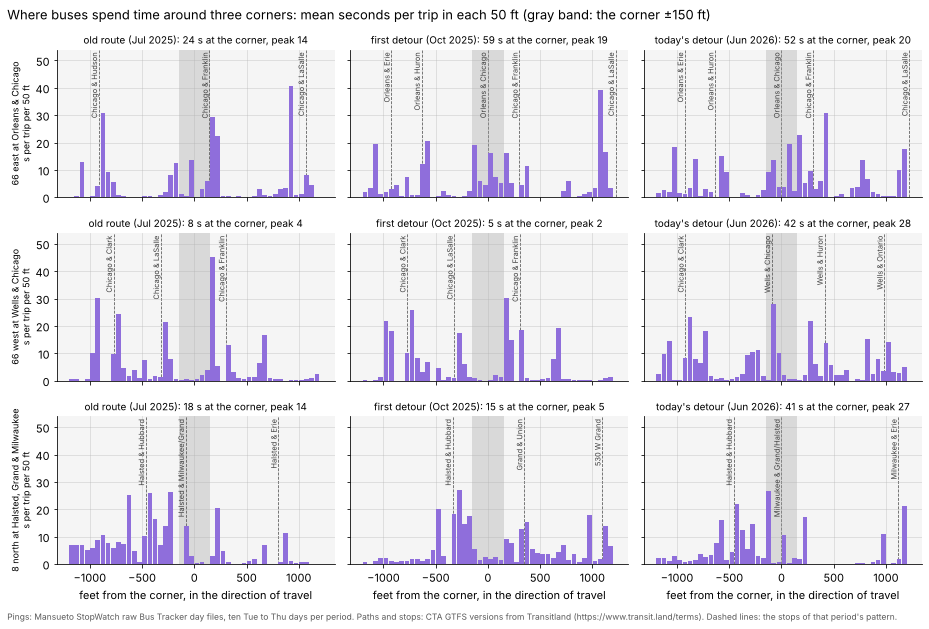

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8.6), sharex=True, sharey=True)
TITLE = {"6662": "66 east at Orleans & Chicago", "6665": "66 west at Wells & Chicago", "9376": "8 north at Halsted, Grand & Milwaukee"}
for i, (pid, corner) in enumerate(CORNERS):
    for j, per in enumerate(PERIOD_DAYS):
        ax = axes[i, j]
        prof, stops = PROFILES[(pid, per)]
        ax.axvspan(-CORNER_FT, CORNER_FT, color="0.85", lw=0, zorder=0)
        ax.bar(prof.index + BIN_FT / 2, prof.values, width=BIN_FT * 0.9, color="C0", zorder=2)
        for s in stops.itertuples():
            ax.axvline(s.x, color="0.35", lw=0.8, ls="--", zorder=1)
            ax.text(s.x, 53, s.name.replace(" (Blue Line)", "").replace(" (Brown line)", ""), rotation=90, fontsize=7.5,
                    va="top", ha="right", color="0.25")
        row = CORNER_TABLE[(CORNER_TABLE["pid"] == pid) & (CORNER_TABLE["period"] == per)].iloc[0]
        ax.set_ylim(0, 54)
        ax.set_title(f"{PERIOD_LABEL[per]}: {row['corner_s']:.0f} s at the corner, peak {row['corner_peak_s']:.0f}", fontsize=10)
        if j == 0:
            ax.set_ylabel(f"{TITLE[pid]}\ns per trip per 50 ft", fontsize=9)
        if i == 2:
            ax.set_xlabel("feet from the corner, in the direction of travel")
fig.suptitle("Where buses spend time around three corners: mean seconds per trip in each 50 ft (gray band: the corner ±150 ft)",
             x=0.01, ha="left", fontsize=13)
fig.text(0.01, -0.01, "Pings: Mansueto StopWatch raw Bus Tracker day files, ten Tue to Thu days per period. Paths and stops: CTA GTFS "
         "versions from Transitland (https://www.transit.land/terms). Dashed lines: the stops of that period's pattern.", fontsize=8.5, color="0.35")
fig.tight_layout()
plt.show()

### 2b. Halsted, Grand & Milwaukee, measured from the intersection centre (owner, 2026-11-28)

Measuring around stop `15341` says little here. The stop stands northwest of the six-way intersection, so a detour
that turns from northbound Halsted onto eastbound Grand never comes near it. Under rule 2, the question is whether
buses stopped anywhere at the intersection. So the band is centred on the intersection: where Halsted crosses Grand in
the schedule's paths (route 8's old path and route 65's), 178 ft southeast of `15341`; Milwaukee crosses Halsted
about 60 ft north of it. Positions are feet along each period's path from where it passes the centre; negative is
the Halsted approach from the south.

In [11]:
MAP_X, MAP_Y = (-1_000, 900), (-750, 1_250)  # feet around stop 15341: Hubbard to the south, Erie to the north, Union to the east
here = TODAY_STOPS.loc["15341"]
KX = FT_PER_DEG_LAT * np.cos(np.radians(41.9))


def map_xy(lat, lon):
    return (np.asarray(lon, float) - here["stop_lon"]) * KX, (np.asarray(lat, float) - here["stop_lat"]) * FT_PER_DEG_LAT


backdrop = []
for path in ("old", "det2"):
    z = zipfile.ZipFile(FEED_DIR / f"{VERSION[path]}.zip")
    trips, shapes = _read(z, "trips.txt"), _read(z, "shapes.txt")
    route_of = trips.drop_duplicates("shape_id").set_index("shape_id")["route_id"]
    bus = set(route_of[route_of.str.fullmatch(r"\d+")].index)
    near = shapes[shapes["shape_id"].isin(bus) & shapes["shape_pt_lat"].between(here["stop_lat"] - 0.006, here["stop_lat"] + 0.006)
                  & shapes["shape_pt_lon"].between(here["stop_lon"] - 0.008, here["stop_lon"] + 0.008)]
    keep = shapes[shapes["shape_id"].isin(set(near["shape_id"]))].copy()
    keep["route_id"] = keep["shape_id"].map(route_of)
    backdrop.append(keep.assign(shape_id=path + keep["shape_id"]))
BACKDROP = pd.concat(backdrop).sort_values(["shape_id", "shape_pt_sequence"])

# the centre: the point of route 8's old (Halsted) path nearest route 65's Grand Avenue path, sampled every 5 ft
halsted = SHAPES[("old", "9376")]
hx, hy = map_xy(halsted["shape_pt_lat"], halsted["shape_pt_lon"])
hd = halsted["shape_dist_traveled"].to_numpy(float)
around = np.arange(hd[np.argmin(np.hypot(hx, hy))] - 600, hd[np.argmin(np.hypot(hx, hy))] + 600, 5)
cand_x, cand_y = np.interp(around, hd, hx), np.interp(around, hd, hy)
cand_lat, cand_lon = here["stop_lat"] + cand_y / FT_PER_DEG_LAT, here["stop_lon"] + cand_x / KX
nearest = np.min([project(g, cand_lat, cand_lon)[1] for _, g in BACKDROP[BACKDROP["route_id"] == "65"].groupby("shape_id")], axis=0)
CENTRE = (float(cand_x[nearest.argmin()]), float(cand_y[nearest.argmin()]))
centre_lat = here["stop_lat"] + CENTRE[1] / FT_PER_DEG_LAT
centre_lon = here["stop_lon"] + CENTRE[0] / KX
print(f"centre at {CENTRE[0]:.0f} ft east, {CENTRE[1]:.0f} ft north of stop 15341 ({np.hypot(*CENTRE):.0f} ft away)")

rows, CENTRE_PROFILES = [], {}
for per in PERIOD_DAYS:
    along, off = project(SHAPES[(per, "9376")], centre_lat, centre_lon)
    at = float(along[0])
    p, n = traversals("9376", per, at)
    prof = profile(p, n)
    CENTRE_PROFILES[per] = (at, prof)
    stops = nearby_stops("9376", per, at, 700)
    near100 = prof[(prof.index >= -100) & (prof.index < 100)]
    m150, se150 = seconds_in(p, n, -150, 150)
    m250, se250 = seconds_in(p, n, -250, 250)
    piles = prof[(prof.index >= -500) & (prof.index < 500) & (prof >= 8)]
    rows.append({"period": per, "trips": n, "centre_off_path_ft": round(float(off[0])),
                 "within_150_s": round(m150, 1), "se_150": round(se150, 1), "within_250_s": round(m250, 1), "se_250": round(se250, 1),
                 "largest_within_100_s": round(near100.max(), 1),
                 "pile_ups_over_8_s (ft: s)": "; ".join(f"{int(b) + 25:+d}: {v:.0f}" for b, v in piles.items()),
                 "scheduled stops (ft)": "; ".join(f"{r.name.replace(' (Blue Line)', '')} {r.x:+.0f}" for r in stops.itertuples())})
CENTRE_TABLE = pd.DataFrame(rows)
display(CENTRE_TABLE)

centre at 101 ft east, -147 ft north of stop 15341 (178 ft away)


,period,trips,centre_off_path_ft,within_150_s,se_150,within_250_s,se_250,largest_within_100_s,pile_ups_over_8_s (ft: s),scheduled stops (ft)
0,old,965,0,57.2,3.8,83.4,4.4,26.4,-475: 26; -325: 10; -275: 25; -225: 18; -125: ...,Halsted & Hubbard -312; Halsted & Milwaukee/Gr...
1,det1,895,23,19.8,2.5,67.2,4.2,2.7,-475: 23; -325: 15; -275: 27; -225: 15; -175: ...,Halsted & Hubbard -323; Grand & Union +361
2,det2,944,7,49.3,3.6,81.6,4.4,25.7,-425: 21; -275: 21; -225: 16; -125: 12; -75: 8...,Halsted & Hubbard -289; Milwaukee & Grand/Hals...


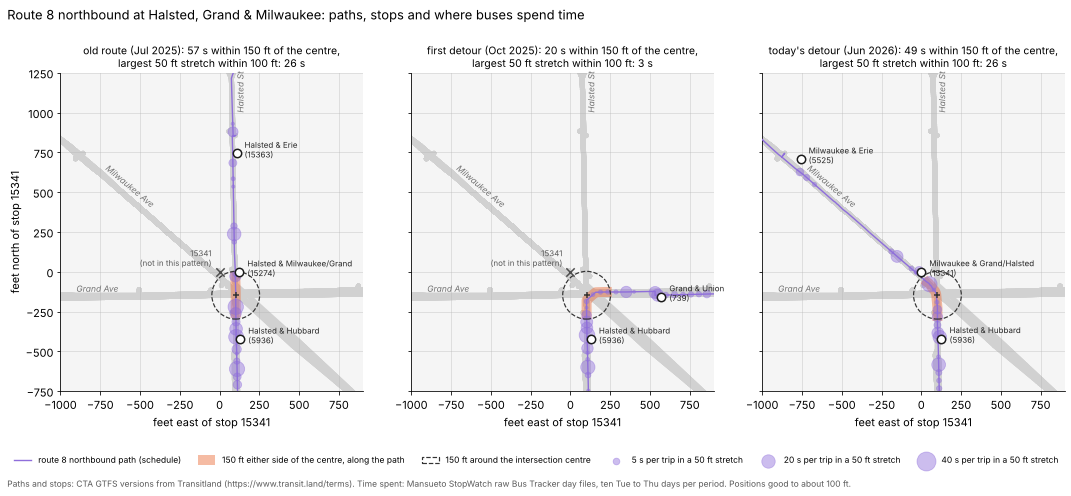

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6.6), sharex=True, sharey=True)
for ax, per in zip(axes, PERIOD_DAYS):
    for _, g in BACKDROP.groupby("shape_id"):
        ax.plot(*map_xy(g["shape_pt_lat"], g["shape_pt_lon"]), color="0.82", lw=5, solid_capstyle="round", zorder=0)
    shape, pattern, stops = SHAPES[(per, "9376")], PATTERN[(per, "9376")], STOPS[per]
    sx, sy = map_xy(shape["shape_pt_lat"], shape["shape_pt_lon"])
    dist = shape["shape_dist_traveled"].to_numpy(float)
    ax.plot(sx, sy, color="C0", lw=1.4, zorder=3, label="route 8 northbound path (schedule)")
    at, prof = CENTRE_PROFILES[per]
    band = np.linspace(at - CORNER_FT, at + CORNER_FT, 60)
    ax.plot(np.interp(band, dist, sx), np.interp(band, dist, sy), color="C1", lw=10, alpha=0.45, solid_capstyle="butt", zorder=2,
            label="150 ft either side of the centre, along the path")
    mids = prof.index.to_numpy() + BIN_FT / 2 + at
    bx, by = np.interp(mids, dist, sx), np.interp(mids, dist, sy)
    keep = (bx > MAP_X[0]) & (bx < MAP_X[1]) & (by > MAP_Y[0]) & (by < MAP_Y[1]) & (prof.to_numpy() >= 1)
    ax.scatter(bx[keep], by[keep], s=prof.to_numpy()[keep] * 9, color="C0", alpha=0.45, edgecolor="C0", lw=0.8, zorder=4)
    ax.add_patch(plt.Circle(CENTRE, CORNER_FT, fill=False, ls="--", lw=1.2, color="0.2", zorder=5, label="150 ft around the intersection centre"))
    ax.scatter(*CENTRE, s=40, marker="+", color="0.2", lw=1.5, zorder=6)
    for s in pattern["stop_id"]:
        x, y = map_xy(stops.loc[s, "stop_lat"], stops.loc[s, "stop_lon"])
        if MAP_X[0] < x < MAP_X[1] and MAP_Y[0] < y < MAP_Y[1]:
            ax.scatter(x, y, s=70, color="white", edgecolor="0.1", lw=1.5, zorder=6)
            ax.annotate(f"{stops.loc[s, 'stop_name'].replace(' (Blue Line)', '')}\n({s})", (x, y), xytext=(8, -4),
                        textcoords="offset points", fontsize=8, color="0.15", zorder=7)
    if "15341" not in set(pattern["stop_id"]):
        ax.scatter(0, 0, s=70, marker="x", color="0.3", lw=1.5, zorder=6)
        ax.annotate("15341\n(not in this pattern)", (0, 0), xytext=(-8, 6), textcoords="offset points", fontsize=8, color="0.35", ha="right")
    for txt, (tx, ty), rot in [("Halsted St", (150, 1000), 90), ("Grand Ave", (-900, -125), 0), ("Milwaukee Ave", (-720, 645), -40)]:
        ax.text(tx, ty, txt, rotation=rot, fontsize=8.5, color="0.45", style="italic", rotation_mode="anchor")
    row = CENTRE_TABLE[CENTRE_TABLE["period"] == per].iloc[0]
    ax.set_title(f"{PERIOD_LABEL[per]}: {row['within_150_s']:.0f} s within 150 ft of the centre,\nlargest 50 ft stretch within 100 ft: {row['largest_within_100_s']:.0f} s", fontsize=10.5)
    ax.set_xlim(*MAP_X); ax.set_ylim(*MAP_Y); ax.set_aspect("equal")
    ax.set_xlabel("feet east of stop 15341")
axes[0].set_ylabel("feet north of stop 15341")
for secs in (5, 20, 40):
    axes[0].scatter([], [], s=secs * 9, color="C0", alpha=0.45, edgecolor="C0", lw=0.8, label=f"{secs} s per trip in a 50 ft stretch")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Route 8 northbound at Halsted, Grand & Milwaukee: paths, stops and where buses spend time", x=0.01, ha="left", fontsize=13)
fig.text(0.01, -0.03, "Paths and stops: CTA GTFS versions from Transitland (https://www.transit.land/terms). Time spent: Mansueto StopWatch "
         "raw Bus Tracker day files, ten Tue to Thu days per period. Positions good to about 100 ft.", fontsize=8.5, color="0.35")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

What the centre-based reading shows. Seconds are mean seconds per trip; the exact values are in `CENTRE_TABLE`.
- **Old route:** about 57 s within 150 ft of the centre. That is the queue for the signal on the Halsted approach,
  plus the far-side stop `15274`, 69 ft past the centre (14 s in one stretch).
- **First detour:** about 20 s, and no 50 ft stretch within 100 ft of the centre on either leg (the Halsted approach,
  or Grand after the right turn) holds more than 3 s. The pile-ups are the queue that runs back from Grand to the
  Hubbard stop, 150 to 350 ft before the centre, and the approach to Grand & Union, from 200 ft after it.
- **Today's detour:** about 49 s, with 26 s just past the centre where buses wait to bear onto Milwaukee, and the stop
  at 168 ft.

So in the first detour no bus routinely stopped at the intersection, on either side. Scheduled stops nearby pile up 14
to 27 s in one stretch. A rarely used stop whose average dwell is a few seconds would not show at this resolution.

## Findings

Measured 2026-11-23, 2026-11-27 and 2026-11-28 from Mansueto raw day files (300 s pings; 50 days around the changes, 30 sample
weekdays) and three archived CTA GTFS versions. Contains data from [Transitland](https://www.transit.land/terms).
Recorded in `docs/2026-11-23-stop-validity-review-driving-and-corners.md`, `docs/2026-11-23-longest-pdist-dating.md`
`docs/2026-11-27-corner-map-and-unreported-days.md` and `docs/2026-11-28-intersection-centre-and-drop.md`.

1. **Rule 1: the actual driving matches the schedule's dates; the committed dates are a day or two off because of how
   they were measured.** Route 66 east left Chicago Avenue on 2025-09-28 (147 pings on the old path on 09-27, 1 after
   midnight on 09-28), not 09-27. Route 66 west and route 8 south took today's detours on 2025-11-23 (100 to 109 pings
   a pid on today's-detour-only streets that day, against 2 to 11 the day before), not 2025-11-24 and 2025-11-25. The other four changes agree
   all three ways. The committed dates came from each calendar day's longest `pdist`, and one trip set each of the
   three that differ (section 1b): a final ping at the terminal already on the new pattern (6662), an owl trip of the
   previous service day after midnight (6665, 9368), and one evening trip measured along the old pattern (9368, 11-24).
   Bus Tracker otherwise measured `pdist` along the path driven (99% to 100% of pings). Under rule 1, 18 committed
   windows move: 6662's eight stops to 2025-09-28 (from 09-27), 6665's
   `6613`, `6614`, `5020`, `769` to 2025-11-23 (from 11-24), and 9368's six Division and Milwaukee stops to 2025-11-23
   (from 11-25).
2. **Before three of the changes, Bus Tracker stopped reporting buses on the closed section.** Route 8 from 2025-08-04
   (the Halsted closure; the buses left Halsted that day) to 2025-08-16, route 8 again from 2025-11-07 to 2025-11-22,
   and route 66 west from 2025-10-31 to 2025-11-22. Every day of the three periods was read (the 19 days skipped on
   2026-11-23 were added on 2026-11-27): 32 to 102 consecutive ping pairs per pid jump the section each day (0 to 22 on
   the other days read), 10 to 20 minutes apart, and almost no ping lies on any of the three paths there; route 66 west
   has 3 to 35 a day on Wells. Rule 1 has nothing to read on those days, and Mansueto's arrivals at stops in the
   section are interpolated across the gap.
   The owner chose to drop arrivals the pings did not observe (2026-11-28). Every stop the pings skipped on those days
   is a stop of today's detour, already dropped by its reviewed window, so "drop" adds only the one trip measured along
   the old pattern on 2025-11-24 (sections 1b and 1c). Mansueto's arrivals past a detour follow the bus, not Bus
   Tracker's pattern (2025-10-14: within 11 s of the GPS passes at the median).
3. **Rule 3, Wells & Chicago (6665 `18803`): not served before the detour reached Wells.** Westbound buses spent
   7.7 ± 1.2 s (old route) and 4.9 ± 1.0 s (first detour) within 150 ft of the corner, against 41.7 ± 2.6 s once the
   stop existed. The pile-ups sit at Chicago & LaSalle and Chicago & Franklin, on either side.
4. **Rule 3, Orleans & Chicago (6662 `6714`): not served before 2025-09-28.** Eastbound buses on Chicago Avenue spent
   24.3 ± 2.0 s at the corner. Westbound buses crossing the same intersection, which never had a stop there, spent
   23.3 ± 2.0 and 27.6 ± 2.3 s, so that is the signal. With the stop, 58.7 ± 3.1 and 52.3 ± 2.9 s.
5. **Rule 3, Halsted, Grand & Milwaukee (9376) during the first detour: no stop at the intersection.** Measured from
   the intersection centre (section 2b; the owner found the band around `15341` uninformative, as the first detour turned
   onto Grand before reaching it), buses spent about 20 s within 150 ft of the centre, against 57 s on the old route
   and 49 s today. No 50 ft stretch within 100 ft of the centre, on either leg, holds more than 3 s. With a stop,
   one stretch holds 14 to 27 s. The pile-ups are the queue back to the Hubbard stop and the approach to Grand & Union,
   the scheduled stops 290 to 360 ft away. A rarely used stop would not show.
6. **The stop-before-to-stop-after times move with the path, not only with the stop.** LaSalle to Franklin on Chicago
   Avenue takes 14.7 and 12.5 s on average (no stop at Wells); today's Clark to Wells & Huron, which turns onto Wells,
   117.1 s. They agree with the corner readings but cannot settle them alone: each corner's stop arrived with a new
   path.
7. **What the review changes** (applied through `specs/mansueto-stop-validity.md`, Rule 2). Confirmed by the owner on
   2026-11-27:
   - the 18 dates of finding 1;
   - new windows for `6714` (from 2025-09-28) and `18803` (from 2025-11-23);
   - the five id changes at a served corner keep their windows (rule 2).

   Decided 2026-11-28: drop the unreported days' unobserved arrivals, which comes down to the one trip of 2025-11-24.
   Still open: `15341` on 9376 not served from 2025-08-17 to 2025-11-22 (finding 5).